<a href="https://colab.research.google.com/github/EmanFatima-38/MNIST/blob/main/MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files
uploaded = files.upload()

Saving mnist_train.csv to mnist_train.csv
Saving mnist_test.csv to mnist_test.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Libraries loaded")

Libraries loaded


In [5]:
train = pd.read_csv("mnist_train.csv")
test = pd.read_csv("mnist_test.csv")

print("Training data shape:", train.shape)
print("Test data shape:", test.shape)
train.head()

Training data shape: (60000, 785)
Test data shape: (10000, 785)


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
print("Missing values in training data:", train.isnull().sum().sum())
print("Missing values in test data:", test.isnull().sum().sum())

Missing values in training data: 0
Missing values in test data: 0


In [7]:
y_train = train["label"].values
X_train = train.drop("label", axis=1).values

y_test = test["label"].values
X_test = test.drop("label", axis=1).values

print("Before normalisation: min =", X_train.min(), " max =", X_train.max())

X_train = X_train / 255.0
X_test = X_test / 255.0

print("After normalisation:  min =", X_train.min(), " max =", X_train.max())
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test:", X_test.shape, " y_test:", y_test.shape)

Before normalisation: min = 0  max = 255
After normalisation:  min = 0.0  max = 1.0
X_train: (60000, 784)  y_train: (60000,)
X_test: (10000, 784)  y_test: (10000,)


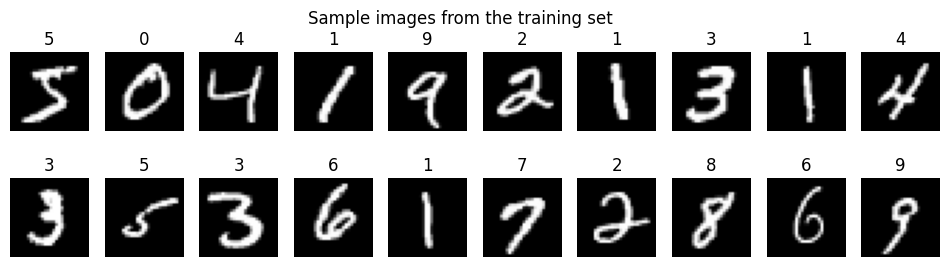

In [8]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(y_train[i])
    ax.axis("off")
plt.suptitle("Sample images from the training set")
plt.show()

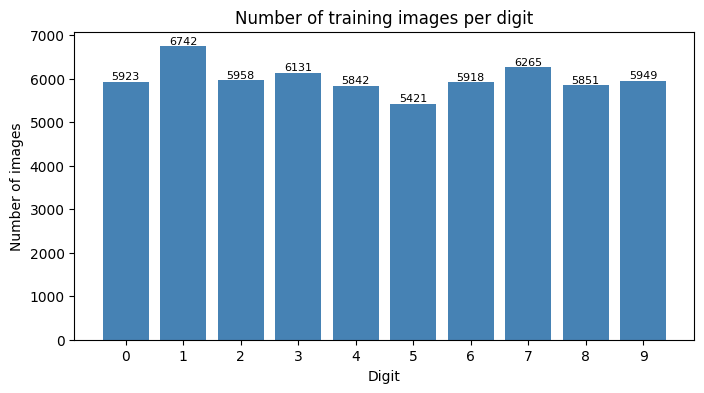

In [9]:
counts = np.bincount(y_train)
plt.figure(figsize=(8, 4))
plt.bar(range(10), counts, color="steelblue")
for d, c in enumerate(counts):
    plt.text(d, c + 50, str(c), ha="center", fontsize=8)
plt.xticks(range(10))
plt.xlabel("Digit"); plt.ylabel("Number of images")
plt.title("Number of training images per digit")
plt.show()

In [10]:
lr = LogisticRegression(max_iter=200, C=0.1)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)
print(f"Logistic Regression accuracy: {lr_acc*100:.2f}%")


Logistic Regression accuracy: 92.58%


In [11]:
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Random Forest accuracy: {rf_acc*100:.2f}%")

Random Forest accuracy: 97.07%


In [13]:
mlp = MLPClassifier(hidden_layer_sizes=(512, 256), activation="relu", solver="adam",
                    batch_size=128, max_iter=30, early_stopping=True,
                    n_iter_no_change=5, random_state=42, verbose=True)
mlp.fit(X_train, y_train)
mlp_pred = mlp.predict(X_test)
mlp_acc = accuracy_score(y_test, mlp_pred)
print(f"Neural Network accuracy: {mlp_acc*100:.2f}%")

Iteration 1, loss = 0.24059982
Validation score: 0.957167
Iteration 2, loss = 0.08608790
Validation score: 0.965833
Iteration 3, loss = 0.05658654
Validation score: 0.972667
Iteration 4, loss = 0.03848497
Validation score: 0.974000
Iteration 5, loss = 0.02919310
Validation score: 0.976167
Iteration 6, loss = 0.02153504
Validation score: 0.974667
Iteration 7, loss = 0.01680047
Validation score: 0.976500
Iteration 8, loss = 0.01387235
Validation score: 0.978167
Iteration 9, loss = 0.01878183
Validation score: 0.974167
Iteration 10, loss = 0.01315104
Validation score: 0.978333
Iteration 11, loss = 0.00943881
Validation score: 0.978333
Iteration 12, loss = 0.01103319
Validation score: 0.975000
Iteration 13, loss = 0.01202141
Validation score: 0.975833
Iteration 14, loss = 0.01199821
Validation score: 0.978833
Iteration 15, loss = 0.01062289
Validation score: 0.980000
Iteration 16, loss = 0.00647370
Validation score: 0.976000
Iteration 17, loss = 0.01278470
Validation score: 0.976000
Iterat

                 Model  Test Accuracy (%)
0  Logistic Regression              92.58
1        Random Forest              97.07
2       Neural Network              98.33


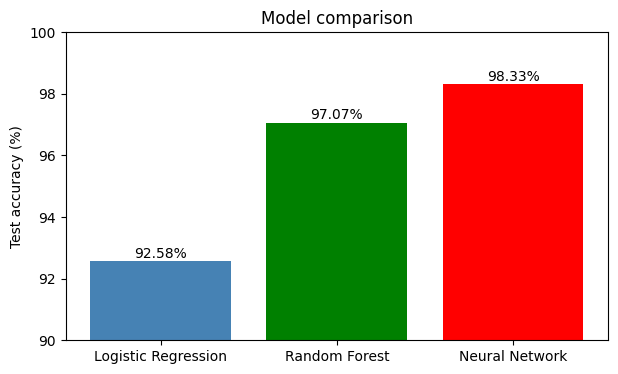

In [15]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "Neural Network"],
    "Test Accuracy (%)": [lr_acc*100, rf_acc*100, mlp_acc*100]
})
print(results.round(2))

plt.figure(figsize=(7, 4))
bars = plt.bar(results["Model"], results["Test Accuracy (%)"], color=["steelblue", "green", "red"])
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 0.1, f"{b.get_height():.2f}%", ha="center")
plt.ylim(90, 100)
plt.ylabel("Test accuracy (%)")
plt.title("Model comparison")
plt.show()

In [17]:
print(classification_report(y_test, mlp_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.99      0.98      0.98      1032
           3       0.98      0.99      0.98      1010
           4       0.98      0.99      0.98       982
           5       0.99      0.97      0.98       892
           6       0.98      0.99      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.98      0.97      0.98       974
           9       0.98      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



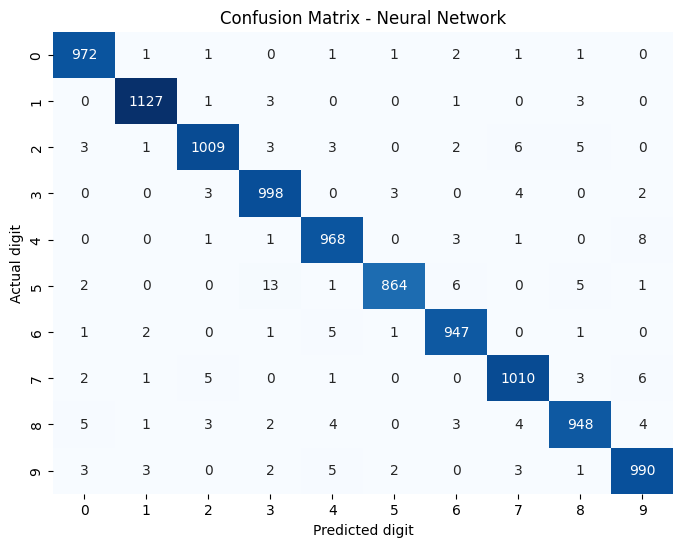

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, mlp_pred), annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted digit"); plt.ylabel("Actual digit")
plt.title("Confusion Matrix - Neural Network")
plt.show()

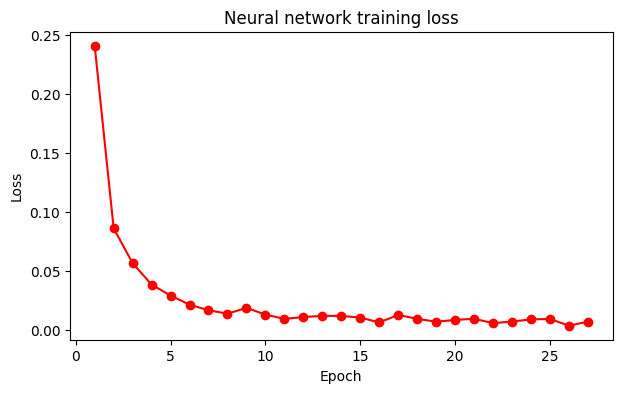

Number of epochs trained: 27


In [19]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, "o-", color="red")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Neural network training loss")
plt.show()
print("Number of epochs trained:", mlp.n_iter_)

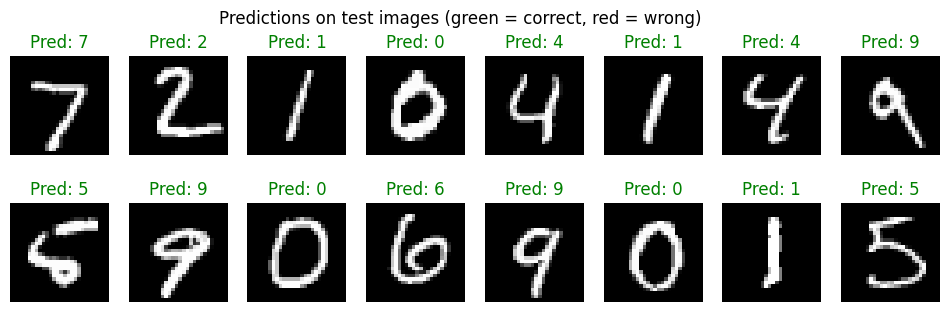

In [20]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    color = "green" if mlp_pred[i] == y_test[i] else "red"
    ax.set_title(f"Pred: {mlp_pred[i]}", color=color)
    ax.axis("off")
plt.suptitle("Predictions on test images (green = correct, red = wrong)")
plt.show()

Total wrong predictions: 167 out of 10000


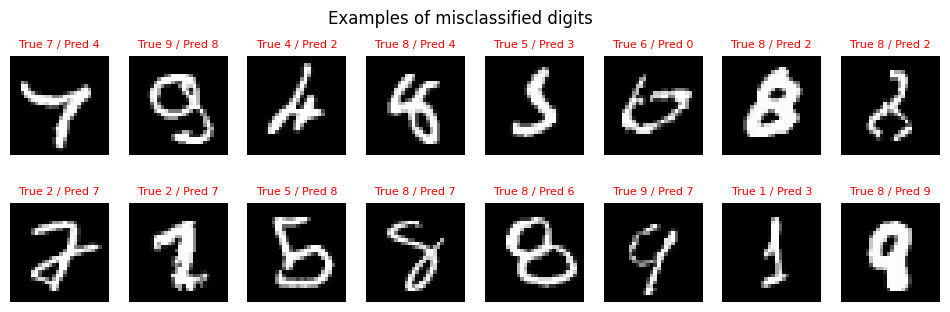

In [21]:
wrong = np.where(mlp_pred != y_test)[0]
print("Total wrong predictions:", len(wrong), "out of", len(y_test))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, wrong[:16]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"True {y_test[i]} / Pred {mlp_pred[i]}", color="red", fontsize=8)
    ax.axis("off")
plt.suptitle("Examples of misclassified digits")
plt.show()

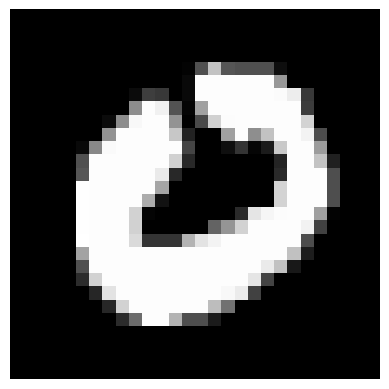

Actual digit:    0
Predicted digit: 0


In [22]:
index = 25        # change this number (0 to 9999) to test different images
plt.imshow(X_test[index].reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()
print("Actual digit:   ", y_test[index])
print("Predicted digit:", mlp.predict([X_test[index]])[0])